# Pilot Building Selection 

---

## Summary

I scored every address in the student directory workbook by how much evidence we hold about it then checked whether each top candidate still exists.

**Selected building: H. B. Quick's, tailor & outfitter.** It was 9 & 10 Widmore Road in 1892 and is **17 & 19 Widmore Road, Bromley BR1 1RL** today.

## 1. Data sources

| Folder / file | What it is |
|---|---|
| `data/Downtown Bromley - Directory Info - 2026-06-02.xlsx` | Student-compiled workbook: ~165 Bromley entries cross-referenced to Strong's 1891/1892, Kelly's 1896 and Bush 1896 directories (3 tabs: Directory, Census, Images) |
| `data/osm_buildings_extract.json` | OpenStreetMap building footprints around the site (Overpass extract, © OpenStreetMap contributors, ODbL) |
| `data/osm_widmore_road_addresses_extract.json` | OpenStreetMap shop points with modern Widmore Road house numbers, and the road centreline |
| `sources/bromley_town_centre_conservation_area_appraisal_2025.pdf` (+ `_text.txt`) | Bromley Council, *Town Centre Conservation Area Appraisal*, June 2025 |
| `images/19widmore.jpg` | 2025 front-elevation photo of modern 17 / 19 / 21 Widmore Road (Auction House London lot, March 2025) |
| `images/Quick.png` | H. B. Quick's advert, Strong's Directory 1892 (Prof. Bilston's gallery) |
| `images/1907-JaegerSpecialPureWoolUnderwear-500.jpeg` | Jaeger advert, the brand Quick stocked (Prof. Bilston's gallery) |
| `images/S.-Collins.png` | Advert for the runner-up candidate (S. Collins, 17 Widmore Road in 1892) |

In [1]:
import re, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import Image, Markdown, display

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

ROOT = Path(".")
DATA, IMAGES = ROOT / "data", ROOT / "images"

BLUE, INK, INK2 = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#e4e3df", "xtick.color": INK2, "ytick.color": INK2,
                     "axes.labelcolor": INK2, "axes.titleweight": "bold", "axes.titlelocation": "left"})

WORKBOOK = DATA / "Downtown Bromley - Directory Info - 2026-06-02.xlsx"
directory = pd.read_excel(WORKBOOK, sheet_name="Directory Info")
census    = pd.read_excel(WORKBOOK, sheet_name="Census Info")
images    = pd.read_excel(WORKBOOK, sheet_name="Images")

def clean(s):
    return None if pd.isna(s) else (re.sub(r"\s+", " ", str(s)).strip() or None)

def house_no(a):
    m = re.match(r"\d+", a) if a else None
    return int(m.group()) if m else None

for t in (directory, census, images):
    t["Address"] = t["Address"].map(clean)
    t["Name"] = t["Name"].map(clean)
    t["no"] = t["Address"].map(house_no)
    t["street"] = t["Address"].map(lambda a: re.sub(r"^\d+\w?\s*", "", a) if a else None)

pd.DataFrame({"rows": [len(directory), len(census), len(images)],
              "unique addresses": [t["Address"].nunique() for t in (directory, census, images)]},
             index=["Directory Info", "Census Info", "Images"])

,rows,unique addresses
Directory Info,166,149
Census Info,176,148
Images,153,139


## 2. Scoring method

Each non-empty **evidence field** is worth one point. Name, Address and Occupation are not counted: nearly every row has them.
| Tab | Evidence fields |
|---|---|
| Directory | page refs in `Strongs 1891`, `Strongs 1892`, `Kelleys 1896`, `Bush 1896`; `Directory Cross Referencing` note |
| Census | `Census Link`, `Census year`, `Household`, `Notes` |
| Images | `Images` plus the two unlabelled columns beside it (extra links and credit) |

Points are summed per address, then **per business**, because a large shop can occupy two plot numbers. Rows with no address (15 East/North Street continuation lines) can't be located and are excluded.

In [2]:
FIELDS = {
    "directory": (directory, ["Strongs 1891", "Strongs 1892", "Kelleys 1896", "Bush 1896", "Directory Cross Referencing"]),
    "census":    (census,    ["Census Link", "Census year", "Household", "Notes"]),
    "images":    (images,    [c for c in ["Images", "Unnamed: 4", "Unnamed: 5"] if c in images.columns]),
}
score = pd.concat(
    {tab: df.dropna(subset=["Address"]).assign(p=df[cols].notna().sum(axis=1)).groupby("Address")["p"].sum()
     for tab, (df, cols) in FIELDS.items()}, axis=1).fillna(0).astype(int)
score["total"] = score.sum(axis=1)
score["occupants"] = directory.dropna(subset=["Address"]).groupby("Address")["Name"].agg(
    lambda s: "; ".join(n for n in dict.fromkeys(s) if n))
score = score.sort_values("total", ascending=False)
print(f"{len(score)} addresses scored; median {score['total'].median():.0f} fields, max {score['total'].max()}")

149 addresses scored; median 3 fields, max 12


## 3. Ranking results

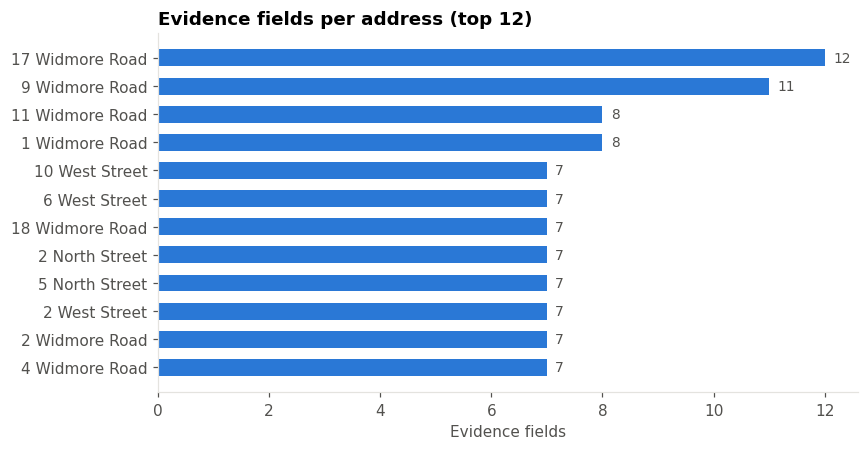

**Per business (multi-plot shops combined):**

,addresses,plots,directory,census,images,total
occupants,,,,,,
Henry Bailey Quick; A Sussenbach,9 Widmore Road + 10 Widmore Road,2,7,4,4,15
Henry G. Cooper,12 Widmore Road + 13 Widmore Road,2,6,6,1,13
S. Collins; J. Tremlett,17 Widmore Road,1,7,4,1,12
William Alexander Grubb,1 Widmore Road,1,3,4,1,8
Thomas Dyer,11 Widmore Road,1,3,4,1,8
T.J. Dafforn,5 Widmore Road,1,3,4,0,7


In [3]:
top = score.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top["total"], color=BLUE, height=0.6)
for y, v in enumerate(top["total"]):
    ax.text(v + 0.15, y, str(v), va="center", color=INK2, fontsize=9)
ax.set_xlabel("Evidence fields")
ax.set_title("Evidence fields per address (top 12)")
plt.tight_layout(); plt.show()

by_business = (score.reset_index().dropna(subset=["occupants"]).groupby("occupants")
               .agg(addresses=("Address", lambda a: " + ".join(sorted(a, key=house_no))),
                    plots=("Address", "size"), directory=("directory", "sum"),
                    census=("census", "sum"), images=("images", "sum"), total=("total", "sum"))
               .sort_values("total", ascending=False))
display(Markdown("**Per business (multi-plot shops combined):**"))
by_business.head(6)

**Findings**

- By address, **17 Widmore Road** ranks first (12), but its fields belong to two unrelated businesses, S. Collins (music seller) and J. Tremlett (Sunridge Farm Dairy).
- By business, **Henry Bailey Quick (9 + 10 Widmore Road)** ranks first with **15 fields**, ahead of H. G. Cooper, butcher (12 + 13, 13 fields) and Collins / Tremlett (17, 12 fields).
- All three leading candidates are on **Widmore Road**, the best-documented commercial street in the workbook.

## 4. The Widmore Road renumbering

The workbook uses 1890s numbers, which ran **consecutively** along the north side of Widmore Road (1–19, then West Street). The street was later renumbered **odd/even** (see the BBLHS note in section 9). If the old run 1, 2, 3… became the odd numbers 1, 3, 5…, then **modern = 2 × old − 1**.

The census notes record some traders at their 1901 address which is after the change. That lets us test the rule against our own data:

In [4]:
pat = re.compile(r"[Ll]isted (?:at|under) (\d+) Widmore [Rr]oad")
tests = []
for _, r in census[census["street"] == "Widmore Road"].iterrows():
    m = pat.search(str(r["Notes"]))
    if m:
        tests.append({"occupant": r["Name"], "1890s no.": int(r["no"]), "1901 census no.": int(m.group(1)),
                      "2n − 1": 2 * int(r["no"]) - 1, "match": int(m.group(1)) == 2 * int(r["no"]) - 1,
                      "note": r["Notes"]})
pd.DataFrame(tests)

,occupant,1890s no.,1901 census no.,2n − 1,match,note
0,George Barrett,4,7,7,True,Listed at 7 Widmore road in 1901 census
1,T.J. Dafforn,5,9,9,True,Listed at 9 Widmore road in 1901 census
2,Henry Bailey Quick; A Sussenbach,9,81,17,False,"Father in Law of William Meeks (other ironmonger in Bromley), list..."


- **Barrett (4 → 7) and Dafforn (5 → 9)** both fit the rule exactly.
- **Quick (9 → 81)** is not a valid test. The note records where he *lived* in 1901 (his son-in-law William Meeks's house), not his shop.

**The rule is adopted with medium-high confidence.** A third, independent check exists in modern OpenStreetMap data: the shop points for modern **15, 19 and 21** sit 6–7 m apart in sequence along the same frontage (section 6), which fits one odd-numbered run. Confirming Quick at 17 & 19 in a post-1902 directory is listed as an open item.

## 5. Which candidates still stand

Each 1890s Widmore Road number is mapped to its modern number and compared with the June 2025 Conservation Area Appraisal (§4.55–4.56):

> "The north side of Widmore Road has a terrace of two storied stock brick buildings (numbers 1-21) all with shopfronts. Number 17 retains its original ornate shopfront with carved colonettes and mirrored soffit above the recessed door."
>
> "24-30; 32-38; and 33-37 Widmore Road are all modern buildings dating from the mid-late twentieth Century"

In [5]:
def status(n):
    if n == 17:  return "standing; ORIGINAL shopfront (CA 4.55)"
    if n <= 21:  return "standing; Victorian terrace (CA 4.55)"
    if 33 <= n <= 37: return "demolished; 20th-c. building (CA 4.56)"
    return "not described in CA; verify"

widmore = (directory[directory["street"] == "Widmore Road"].drop_duplicates("Address")
           [["Address", "no", "Name", "Occupation/House"]].copy())
widmore["modern no."] = widmore["no"].astype(int) * 2 - 1
widmore["status today"] = widmore["modern no."].map(status)
widmore["evidence"] = widmore["Address"].map(score["total"])
widmore.drop(columns="no").reset_index(drop=True)

,Address,Name,Occupation/House,modern no.,status today,evidence
0,1 Widmore Road,William Alexander Grubb,Builder,1,standing; Victorian terrace (CA 4.55),8
1,2 Widmore Road,Herbert Goulden,Chemist,3,standing; Victorian terrace (CA 4.55),7
2,3 Widmore Road,John Dunstall; Pretty Messrs.,Baker & Confectioner; Dentist,5,standing; Victorian terrace (CA 4.55),4
3,4 Widmore Road,George Barrett,Fishmonger & Poulterer,7,standing; Victorian terrace (CA 4.55),7
4,5 Widmore Road,T.J. Dafforn,Draper,9,standing; Victorian terrace (CA 4.55),7
5,6 Widmore Road,Batchelar and Son,Cabinet Makers & Upholsterers,11,standing; Victorian terrace (CA 4.55),6
6,7 Widmore Road,Issac Watts,Grocer,13,standing; Victorian terrace (CA 4.55),6
7,8 Widmore Road,Turner,Oil & Colourmen,15,standing; Victorian terrace (CA 4.55),3
8,9 Widmore Road,Henry Bailey Quick; A Sussenbach,Tailor and outfitter,17,standing; ORIGINAL shopfront (CA 4.55),11
9,10 Widmore Road,Henry Bailey Quick; A Sussenbach,Tailor and outfitter,19,standing; Victorian terrace (CA 4.55),4


## 6. Locating the building today

Two checks confirm that the 1892 plots 9 & 10 are today's 17 & 19, and that the building is there.

**Footprints.** OpenStreetMap shop points carry modern house numbers (e.g. the café at no. 19 and the hardware shop at no. 21). Each building footprint containing one of those points is matched to its number. No. 17 has no shop point, so it is matched as the footprint between nos. 15 and 19.

In [6]:
LAT0, LON0, R = 51.40619, 0.01610, 6371000.0
def to_m(lat, lon):
    return ((lon - LON0) * math.pi / 180 * R * math.cos(math.radians(LAT0)), (lat - LAT0) * math.pi / 180 * R)

def inside(pt, poly):
    x, y = pt; c = False
    for (x1, y1), (x2, y2) in zip(poly, poly[1:]):
        if (y1 > y) != (y2 > y) and x < (x2 - x1) * (y - y1) / (y2 - y1) + x1:
            c = not c
    return c

bld = json.load(open(DATA / "osm_buildings_extract.json"))["elements"]
addr = json.load(open(DATA / "osm_widmore_road_addresses_extract.json"))["elements"]
shops = {e["tags"]["addr:housenumber"]: to_m(e["lat"], e["lon"])
         for e in addr if e["type"] == "node" and "addr:housenumber" in e.get("tags", {})}
display(pd.DataFrame([(k, *map(lambda v: round(v, 1), v)) for k, v in shops.items()],
                     columns=["modern no.", "E (m)", "N (m)"]).set_index("modern no.").T)

footprints = {}
for e in bld:
    poly_m = [to_m(p["lat"], p["lon"]) for p in e["geometry"]]
    for no in ["15", "19", "21"]:
        if no in shops and inside(shops[no], poly_m):
            footprints[no] = {"osm_id": e["id"], "lonlat": [[p["lon"], p["lat"]] for p in e["geometry"]], "m": poly_m}
# no. 17 has no OSM shop point: it is the footprint sharing the party walls between 15 and 19
for e in bld:
    if e["id"] in {f["osm_id"] for f in footprints.values()}: continue
    poly_m = [to_m(p["lat"], p["lon"]) for p in e["geometry"]]
    mid = ((shops["15"][0] + shops["19"][0]) / 2, (shops["15"][1] + shops["19"][1]) / 2 - 2)
    if inside(mid, poly_m):
        footprints["17"] = {"osm_id": e["id"], "lonlat": [[p["lon"], p["lat"]] for p in e["geometry"]], "m": poly_m}

def area(p): return abs(sum(x1 * y2 - x2 * y1 for (x1, y1), (x2, y2) in zip(p, p[1:]))) / 2
def front_edge(p):
    a, b = sorted(p[:-1], key=lambda v: v[1])[:2]         # two most southerly vertices = street frontage
    return sorted([a, b])
rows = []
for no in ["15", "17", "19", "21"]:
    f = footprints[no]; (ax_, ay), (bx, by) = front_edge(f["m"])
    f["front"] = ((ax_, ay), (bx, by))
    depth = max(y for _, y in f["m"]) - min(y for _, y in f["m"])
    rows.append({"modern no.": no, "osm_id": f["osm_id"], "footprint m²": round(area(f["m"]), 1),
                 "frontage m": round(math.dist((ax_, ay), (bx, by)), 2), "max depth m": round(depth, 1)})
fp_table = pd.DataFrame(rows).set_index("modern no.")
fp_table

modern no.,27,10,8,3,9,11 - 13,25A,15,7,6,20,37,33,31,29a,23,21a,19,21
E (m),59.3,-0.5,-11.5,-24.5,-4.9,5.2,50.5,14.1,-12.5,-19.1,53.3,91.1,81.1,75.2,64.6,38.7,33.3,26.8,33.7
N (m),2.1,-27.9,-28.8,-10.9,-7.5,-6.0,0.5,-4.9,-8.5,-30.7,-26.2,7.4,6.0,5.1,3.7,-2.5,-1.3,-2.3,-4.5


,osm_id,footprint m²,frontage m,max depth m
modern no.,,,,
15,961975150,289.9,6.48,42.4
17,961975151,96.7,6.18,19.3
19,961975152,134.2,6.54,21.3
21,961975153,155.6,6.94,29.0


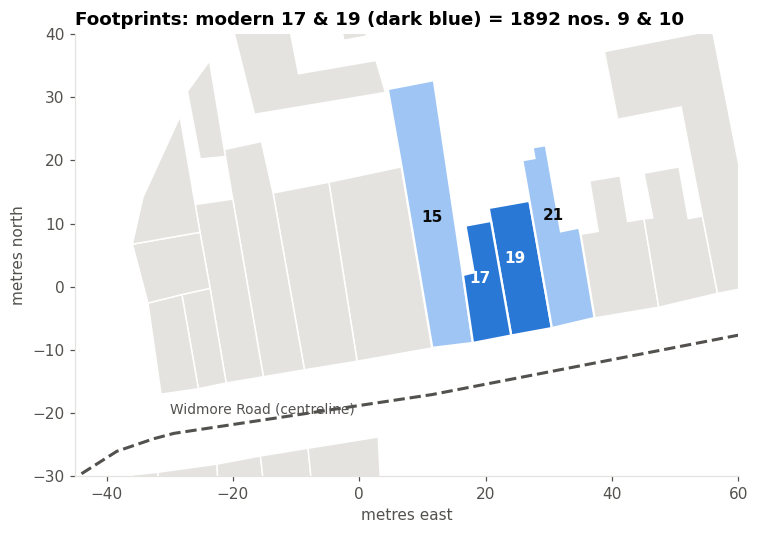

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
for e in bld:
    p = np.array([to_m(q["lat"], q["lon"]) for q in e["geometry"]])
    if np.hypot(*p.mean(axis=0)) < 60:
        ax.fill(p[:, 0], p[:, 1], color="#e4e3df", ec="white", lw=1)
for no, f in footprints.items():
    p = np.array(f["m"])
    target = no in ("17", "19")
    ax.fill(p[:, 0], p[:, 1], color=BLUE if target else "#9ec5f4", ec="white", lw=1.5)
    cx, cy = p[:-1].mean(axis=0)
    ax.text(cx, cy, no, ha="center", va="center", color="white" if target else INK, fontweight="bold")
road = next(e for e in addr if e["type"] == "way" and e["id"] == 5730767)
rp = np.array([to_m(q["lat"], q["lon"]) for q in road["geometry"]])
ax.plot(rp[:, 0], rp[:, 1], color=INK2, lw=2, ls="--"); ax.text(-30, -20, "Widmore Road (centreline)", color=INK2, fontsize=9)
ax.set_aspect("equal"); ax.set_xlim(-45, 60); ax.set_ylim(-30, 40)
ax.set_xlabel("metres east"); ax.set_ylabel("metres north")
ax.set_title("Footprints: modern 17 & 19 (dark blue) = 1892 nos. 9 & 10")
plt.tight_layout(); plt.show()

**Findings**

- Modern **15, 17, 19 and 21** sit side by side in one continuous run, each about **6–7 m** wide. That is one odd-numbered sequence on a single frontage, which fits the 2n − 1 rule from section 4.
- Nos. **17 and 19** are two adjacent plots, **12.7 m** wide together. This matches the record of Quick occupying two neighbouring shops (both units by 1896).
- OSM footprints are traced from aerial imagery and may be off by ±0.5–1 m. That is accurate enough to locate the building, not to survey it.

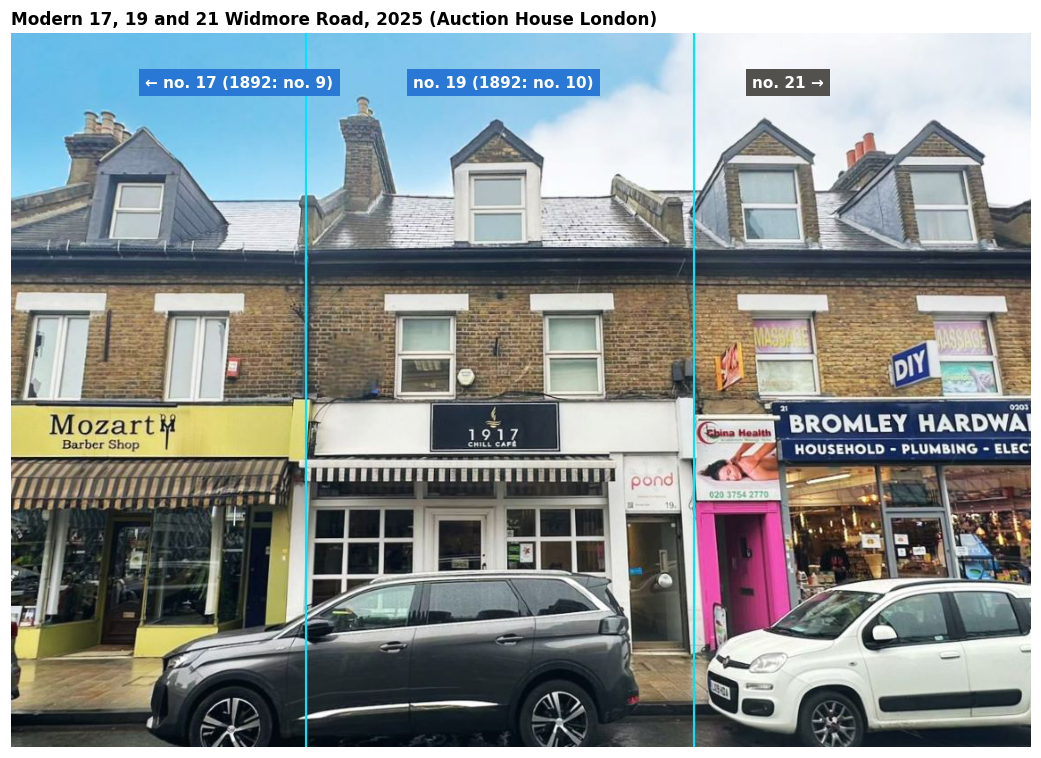

In [8]:
img = mpimg.imread(IMAGES / "19widmore.jpg")
fig, ax = plt.subplots(figsize=(10, 7)); ax.imshow(img); ax.axis("off")
for x in (330, 765):
    ax.axvline(x, color="#00e5ff", lw=1.4)
ax.text(150, 60, "← no. 17 (1892: no. 9)", color="white", fontsize=10, fontweight="bold", bbox=dict(fc=BLUE, lw=0))
ax.text(450, 60, "no. 19 (1892: no. 10)", color="white", fontsize=10, fontweight="bold", bbox=dict(fc=BLUE, lw=0))
ax.text(830, 60, "no. 21 →", color="white", fontsize=10, fontweight="bold", bbox=dict(fc=INK2, lw=0))
ax.set_title("Modern 17, 19 and 21 Widmore Road, 2025 (Auction House London)", fontsize=11)
plt.tight_layout(); plt.show()

**The 2025 photo** shows the building in use and matches the Conservation Area Appraisal's description:

- Two storeys of **yellow stock brick** under a continuous slate roof, part of the same terrace as its neighbours.
- **Two first-floor windows per shop**, with flat lintels and a regular rhythm across the terrace.
- **No. 17** (left, now a barber's) keeps the original shopfront the appraisal describes. **No. 19** (centre) has a modern front, plus a separate door (19A) to the upper floors.

There are also visible later changes: replacement windows, roof dormers, and modern fascias. These don't affect the selection, but anyone reconstructing the 1890s appearance should not copy them.

## 7. Selection

| Candidate | 1890s no. | Modern no. | Evidence | Survives? |
|---|---|---|---|---|
| **H. B. Quick, tailor & outfitter** | **9 & 10** | **17 & 19** | **15** | ✅ Yes, with the original shopfront at 17 |
| H. G. Cooper, butcher | 12 & 13 | 23 & 25 | 13 | ❓ Outside the terrace the appraisal describes |
| S. Collins / J. Tremlett | 17 | 33 | 12 | ❌ Replaced in the 20th century |

**Decision: H. B. Quick's, modern 17 & 19 Widmore Road.** It has the most evidence, and it is the only candidate whose 1890s fabric can be photographed and measured. That makes it the pilot where AI-generated detail can be scored against a real building (the ground-truth principle in the technical plan).

## 8. Building history

What the sources say about the building and its occupants:

In [9]:
q = ["9 Widmore Road", "10 Widmore Road"]
display(Markdown("**Directory rows** (numbers are page references)"))
display(directory.loc[directory["Address"].isin(q), ["Address", "Name", "Occupation/House"] + FIELDS["directory"][1]])
display(Markdown("**Census row**"))
display(census.loc[census["Address"].isin(q) & census["Census year"].notna(),
                   ["Address", "Census year", "Household", "Notes", "Census Link"]])
display(Markdown("**Image rows**"))
display(images.loc[images["Address"].isin(q), ["Address"] + FIELDS["images"][1]])

**Directory rows** (numbers are page references)

,Address,Name,Occupation/House,Strongs 1891,Strongs 1892,Kelleys 1896,Bush 1896,Directory Cross Referencing
8,9 Widmore Road,Henry Bailey Quick; A Sussenbach,Tailor and outfitter,NaN,173.0,10.0,204.0,"Sussenbach in 1892 directory, not in 1896, presumably left and Qui..."
9,10 Widmore Road,Henry Bailey Quick; A Sussenbach,Tailor and outfitter,NaN,173.0,10.0,204.0,NaN


**Census row**

,Address,Census year,Household,Notes,Census Link
9,9 Widmore Road,1901.0,"Father in law to William Meeks (head), lived with his wife, Louisa...","Father in Law of William Meeks (other ironmonger in Bromley), list...",https://ukcensusonline.com/search/advanced/census/main-household/?...


**Image rows**

,Address,Images,Unnamed: 4,Unnamed: 5
8,9 Widmore Road,https://sbilston.domains.trincoll.edu/Shortlandsimages/wp-content/...,Jaeger Wool: https://digital.cincinnatilibrary.org/digital/collect...,Via the Cincinnati & Hamilton County Public Library
9,10 Widmore Road,https://sbilston.domains.trincoll.edu/Shortlandsimages/wp-content/...,NaN,NaN


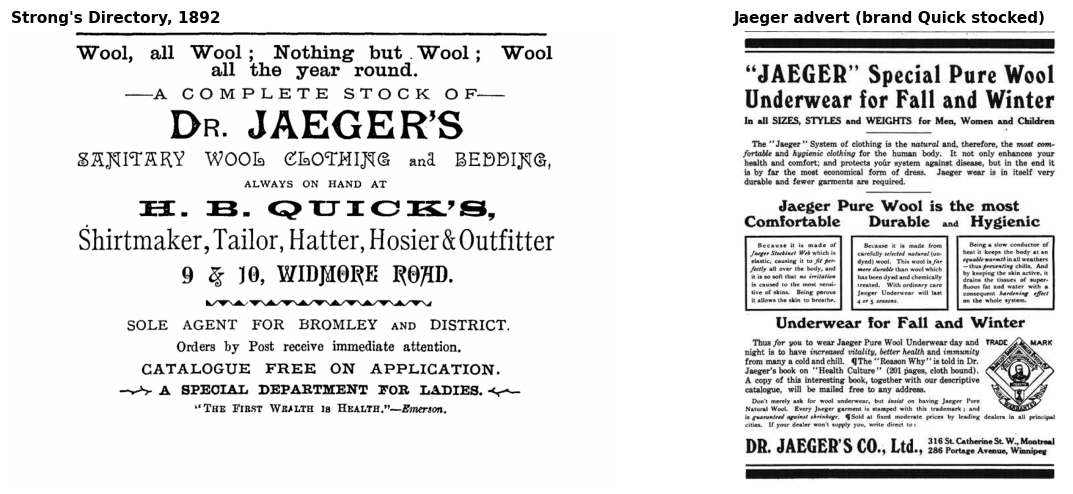

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.35, 0.75]})
for ax, f, t in [(axes[0], "Quick.png", "Strong's Directory, 1892"), (axes[1], "1907-JaegerSpecialPureWoolUnderwear-500.jpeg", "Jaeger advert (brand Quick stocked)")]:
    ax.imshow(mpimg.imread(IMAGES / f)); ax.set_title(t, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

**Timeline**

| Year | Event | Source |
|---|---|---|
| mid-Victorian | North-side terrace (modern 1–21) built: two storeys, stock brick, shopfronts | CA appraisal §4.55 |
| 1891 | Not found in Strong's 1891 | Workbook |
| 1892 | **H. B. Quick** and **A. Sussenbach** both listed at 9 & 10. Quick advertises as "Shirtmaker, Tailor, Hatter, Hosier & Outfitter", sole Bromley agent for Dr. Jaeger's Sanitary Wool clothing, with a "special department for ladies" | Strong's 1892 p.173 & advert |
| 1896 | Sussenbach gone. **Quick occupies both units** | Kelly's 1896 p.10; Bush 1896 p.204 |
| 1901 | Henry Bailey Quick (with wife Louisa) living at 81 Widmore Road with son-in-law William Meeks, ironmonger, and family | 1901 census |
| after 1902 | Street renumbered odd/even: 9 → 17, 10 → 19 | Section 4 |
| 2025 | 17 = barber's (original shopfront retained); 19 = café, with 19A offices above. Sold at auction, March 2025 | CA appraisal; auction listing |

**Note:** 1892 shows **two shopfronts** (Quick + Sussenbach). From c.1896 there is **one double-fronted business**. Pick the target year before texturing the signage.

**Neighbours (1892), for street context:** 8 (now 15): Turner, oil & colourmen · 11 (now 21): Thomas Dyer, Cinderella Boot Stores · 12–13 (now 23–25): H. G. Cooper, butcher.

## 9. Sources

- Student workbook: `data/Downtown Bromley - Directory Info - 2026-06-02.xlsx` (Strong's 1891/1892, Kelly's 1896, Bush 1896 cross-references; census links; image links)
- London Borough of Bromley, [*Bromley Town Centre Conservation Area Appraisal and Management Plan*, June 2025](https://www.bromley.gov.uk/downloads/file/3730/bromley-town-centre-ca-appraisal-and-management-plan-june-2025-): §2.13, §4.54–4.56 (copy in `sources/`)
- Bromley Borough Local History Society, [Curwood shops](https://www.bblhs.org.uk/curwood-shops): Widmore Road odd/even numbering
- 1901 census, [H. B. Quick household](https://ukcensusonline.com/search/advanced/census/main-household/?hlt=125128344&county=279&y=1901&household_id=2103874&a=Search&hh=1&hs=1&cl=1&sscid=279&view_type=fullRecord&v=24)
- Prof. S. Bilston, Shortlands images gallery: [Quick advert (Strong's 1892)](https://sbilston.domains.trincoll.edu/Shortlandsimages/wp-content/gallery/1892-strongs-directory/Quick.png), [Jaeger 1907 advert](https://sbilston.domains.trincoll.edu/Shortlandsimages/wp-content/gallery/external-resources/1907-JaegerSpecialPureWoolUnderwear-500.jpeg)
- [Cincinnati & Hamilton County Public Library: Jaeger advert](https://digital.cincinnatilibrary.org/digital/collection/p16998coll76/id/15655); [Gjenvick Archives: Jaeger ads](https://www.gjenvick.com/VintageFashions/Ads/DrJaegersSanitoryWoollenSystem.html)
- Auction House London, [Lot 38: 19 & 19A Widmore Road](https://auctionhouselondon.co.uk/lot/19-and-19a-widmore-road-bromley-kent-br1-1rl-282601) (photo `images/19widmore.jpg`)
- OpenStreetMap contributors (ODbL), ways 961975151 (no. 17), 961975152 (no. 19); Overpass API extract, Nov 2026
- [postcodes.io](https://postcodes.io): BR1 1RL centroid